# Task 3 · Credit Card Fraud Detection (Imbalanced Data)

**Goal:** build a pipeline that spots fraudulent transactions in a dataset where fraud is very rare, so the **class imbalance** is the main problem to solve.

**Plan**

1. Load the data and measure how rare fraud really is
2. EDA – transaction amounts and time of day for fraud vs. legit, plus the other features
3. Why plain accuracy is a trap on this kind of data
4. Handle the imbalance (`class_weight='balanced'` and SMOTE) and split the data with stratification
5. Train Logistic Regression and Random Forest (each one with no fix, with class weights, and with SMOTE)
6. Evaluate with Precision, Recall, F1, ROC-AUC and Precision-Recall curves, then check the results with 5-fold cross-validation
7. Which metric matters, threshold choice, feature importance
8. Scalability: could this run on 1 million transactions per hour?

**Dataset:** `credit_card_fraud_10k.csv` – 10,000 transactions with columns `amount`, `transaction_hour`, `merchant_category`, `foreign_transaction`, `location_mismatch`, `device_trust_score`, `velocity_last_24h` (how many transactions the card made in the last 24 hours), `cardholder_age` and the target `is_fraud` (1 = fraud).

In [25]:
# Only needed once, if a package is missing:
# !pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

In [26]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score, fbeta_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve, accuracy_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# SMOTENC = SMOTE for data that has both numeric and categorical/binary columns (ours does)
from imblearn.over_sampling import SMOTENC

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# same colours in every chart: blue = legit, red = fraud
COLORS = {"Legit": "#4f7cac", "Fraud": "#c0504d"}

## 1 · Load the data and check the class imbalance

In [27]:
candidates = [Path("credit_card_fraud_10k.csv"), Path("/mnt/user-data/uploads/credit_card_fraud_10k.csv")]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("credit_card_fraud_10k.csv not found - keep it next to this notebook.")

df = pd.read_csv(data_path)
print("Shape:", df.shape)
df.head()

Shape: (10000, 10)


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [28]:
print("Missing values :", int(df.isna().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))
print("Target values  :", sorted(df["is_fraud"].unique()))
print()
print(df.dtypes)

Missing values : 0
Duplicate rows : 0
Target values  : [np.int64(0), np.int64(1)]

transaction_id           int64
amount                 float64
transaction_hour         int64
merchant_category       object
foreign_transaction      int64
location_mismatch        int64
device_trust_score       int64
velocity_last_24h        int64
cardholder_age           int64
is_fraud                 int64
dtype: object


Legit transactions : 9,849 (98.49%)
Fraud transactions : 151 (1.51%)
That is about 1 fraud for every 65 legit transactions.


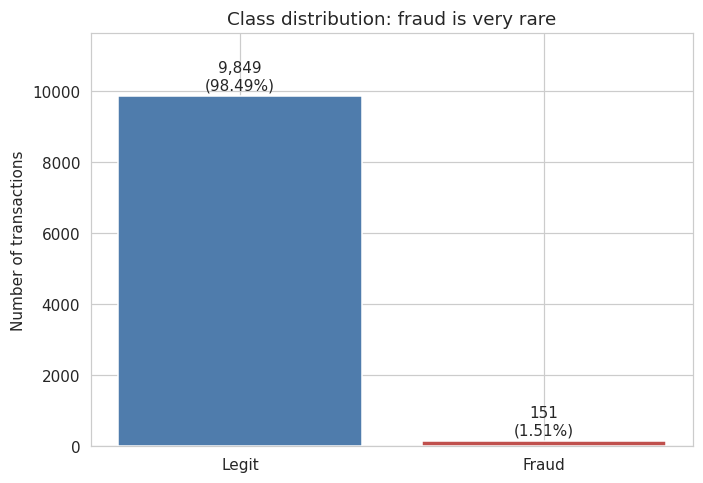

In [29]:
# transaction_id is only a row number. It says nothing about fraud, so it is not used as a feature.
df = df.drop(columns=["transaction_id"])

# readable label for the plots
df["class_label"] = df["is_fraud"].map({0: "Legit", 1: "Fraud"})

n_total = len(df)
n_fraud = int(df["is_fraud"].sum())
n_legit = n_total - n_fraud
fraud_pct = n_fraud / n_total * 100

print(f"Legit transactions : {n_legit:,} ({100 - fraud_pct:.2f}%)")
print(f"Fraud transactions : {n_fraud:,} ({fraud_pct:.2f}%)")
print(f"That is about 1 fraud for every {n_legit / n_fraud:.0f} legit transactions.")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(["Legit", "Fraud"], [n_legit, n_fraud], color=[COLORS["Legit"], COLORS["Fraud"]])
for bar, value in zip(bars, [n_legit, n_fraud]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + n_legit * 0.01,
            f"{value:,}\n({value / n_total:.2%})", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, n_legit * 1.18)
ax.set_ylabel("Number of transactions")
ax.set_title("Class distribution: fraud is very rare")
plt.tight_layout()
plt.show()

**Observation:** fraud makes up only about **1.5%** of the transactions – roughly 1 in 66. With so few fraud examples (151 in total) the model has very little to learn from, and as we will see below, the usual accuracy number hides this problem completely.

## 2 · Exploratory data analysis

### 2.1 Transaction amount: fraud vs. legit

A common assumption is "fraudsters make big purchases". Let's check if that is true in this data.

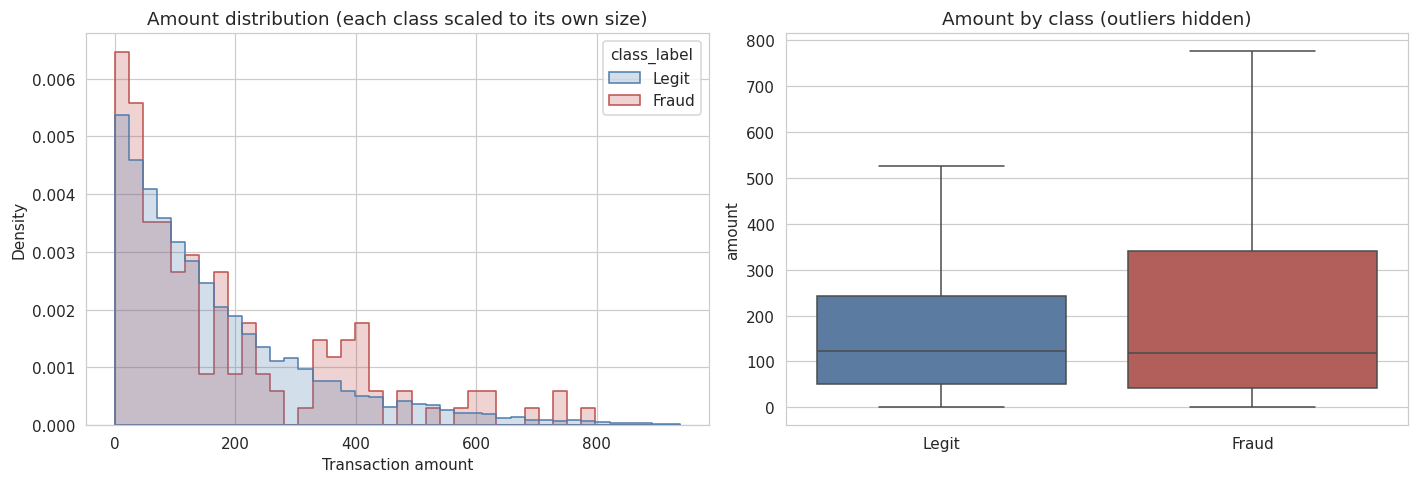

,count,mean,std,min,25%,50%,75%,95%,max
class_label,,,,,,,,,
Fraud,151.0,216.2,248.1,0.1,41.5,118.9,341.7,741.2,1185.1
Legit,9849.0,175.3,174.0,0.0,51.0,122.1,241.6,528.8,1471.0


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# left: distribution (clipped at the 99.5th percentile so a few huge values don't squash the chart)
upper = df["amount"].quantile(0.995)
sns.histplot(data=df[df["amount"] <= upper], x="amount", hue="class_label", hue_order=["Legit", "Fraud"],
             palette=COLORS, stat="density", common_norm=False, element="step", bins=40, ax=axes[0])
axes[0].set_title("Amount distribution (each class scaled to its own size)")
axes[0].set_xlabel("Transaction amount")

# right: boxplot
sns.boxplot(data=df, x="class_label", y="amount", hue="class_label", order=["Legit", "Fraud"],
            hue_order=["Legit", "Fraud"], palette=COLORS, legend=False, showfliers=False, ax=axes[1])
axes[1].set_title("Amount by class (outliers hidden)")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

df.groupby("class_label")["amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(1)

In [31]:
# fraud rate in each amount band (5 equal-sized bands)
df["amount_band"] = pd.qcut(df["amount"], 5)
amount_table = df.groupby("amount_band", observed=True)["is_fraud"].agg(fraud_count="sum", transactions="count")
amount_table["fraud_rate_%"] = (amount_table["fraud_count"] / amount_table["transactions"] * 100).round(2)
amount_table

,fraud_count,transactions,fraud_rate_%
amount_band,,,
"(-0.001, 39.354]",34,2000,1.70
"(39.354, 90.482]",28,2000,1.40
"(90.482, 160.386]",25,2000,1.25
"(160.386, 285.798]",23,2000,1.15
"(285.798, 1471.04]",41,2000,2.05


**Observation:** the amount is **not** a strong signal here. The fraud and legit distributions overlap almost completely, the typical (median) amount is nearly the same (about 119 vs. 122), and the fraud rate stays between roughly 1% and 2% in every amount band. Fraud shows a slightly longer tail of big amounts, but "high amount = fraud" would catch very little. A rule based on amount alone would fail, so the model has to find the pattern elsewhere.

### 2.2 Time of day

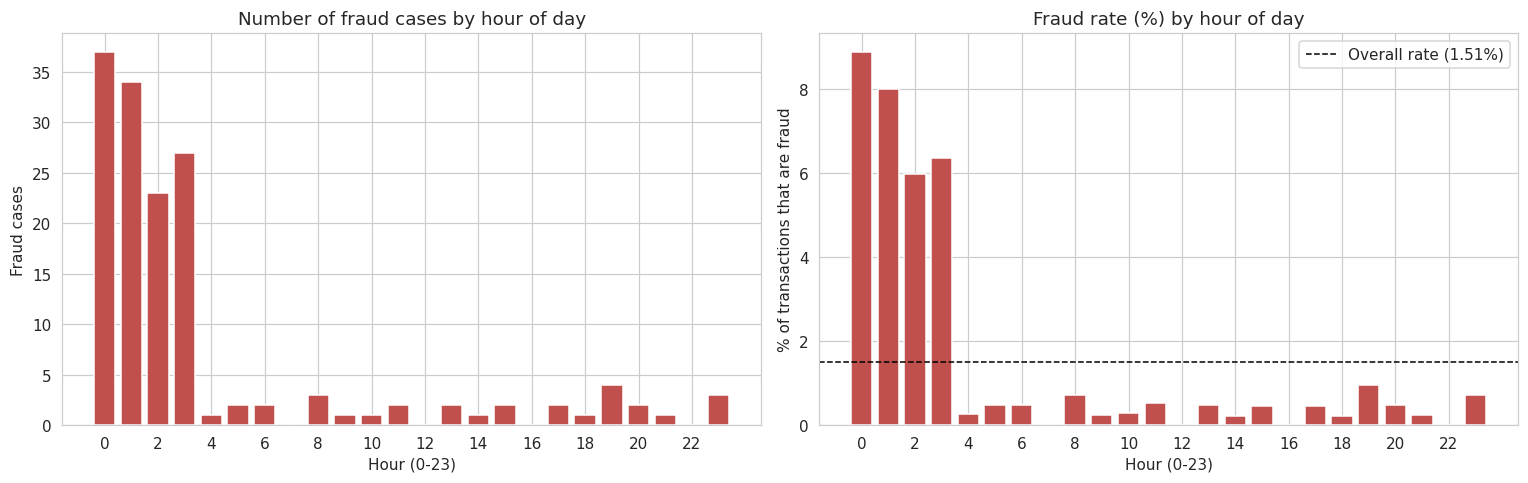

In [32]:
hourly = df.groupby("transaction_hour")["is_fraud"].agg(fraud_count="sum", transactions="count")
hourly["fraud_rate_%"] = hourly["fraud_count"] / hourly["transactions"] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(hourly.index, hourly["fraud_count"], color=COLORS["Fraud"])
axes[0].set_title("Number of fraud cases by hour of day")
axes[0].set_xlabel("Hour (0-23)")
axes[0].set_ylabel("Fraud cases")

axes[1].bar(hourly.index, hourly["fraud_rate_%"], color=COLORS["Fraud"])
axes[1].axhline(fraud_pct, color="black", linestyle="--", linewidth=1, label=f"Overall rate ({fraud_pct:.2f}%)")
axes[1].set_title("Fraud rate (%) by hour of day")
axes[1].set_xlabel("Hour (0-23)")
axes[1].set_ylabel("% of transactions that are fraud")
axes[1].legend()

for ax in axes:
    ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.show()

In [33]:
# Fraud is concentrated in the first hours of the day. I turn that into a simple flag.
# (The 0-3 window comes from the chart above. Strictly, such a cut-off should be decided on the
# training data only; the pattern is so clear here that it makes no practical difference.)
df["is_late_night"] = df["transaction_hour"].between(0, 3).astype(int)

time_bands = pd.cut(df["transaction_hour"], bins=[-1, 3, 11, 17, 23],
                    labels=["00-03", "04-11", "12-17", "18-23"])
band_table = df.groupby(time_bands, observed=True)["is_fraud"].agg(fraud_count="sum", transactions="count")
band_table["fraud_rate_%"] = (band_table["fraud_count"] / band_table["transactions"] * 100).round(2)
band_table["share_of_all_fraud_%"] = (band_table["fraud_count"] / n_fraud * 100).round(1)
band_table

,fraud_count,transactions,fraud_rate_%,share_of_all_fraud_%
transaction_hour,,,,
00-03,121,1652,7.32,80.1
04-11,12,3234,0.37,7.9
12-17,7,2577,0.27,4.6
18-23,11,2537,0.43,7.3


**Observation:** this is the strongest pattern so far. Transactions are spread evenly across the day, but **fraud is concentrated between midnight and 3:59 am** – that window holds about 80% of all fraud cases and its fraud rate (about 7%) is roughly 20 times higher than in the rest of the day (about 0.3–0.4%). After 4 am it drops back to normal.

That is not a smooth trend (4 am and 5 am look normal again), so the raw hour number would be awkward for a linear model. I therefore created a simple `is_late_night` flag and use it in place of the raw hour.

### 2.3 What about the other features?

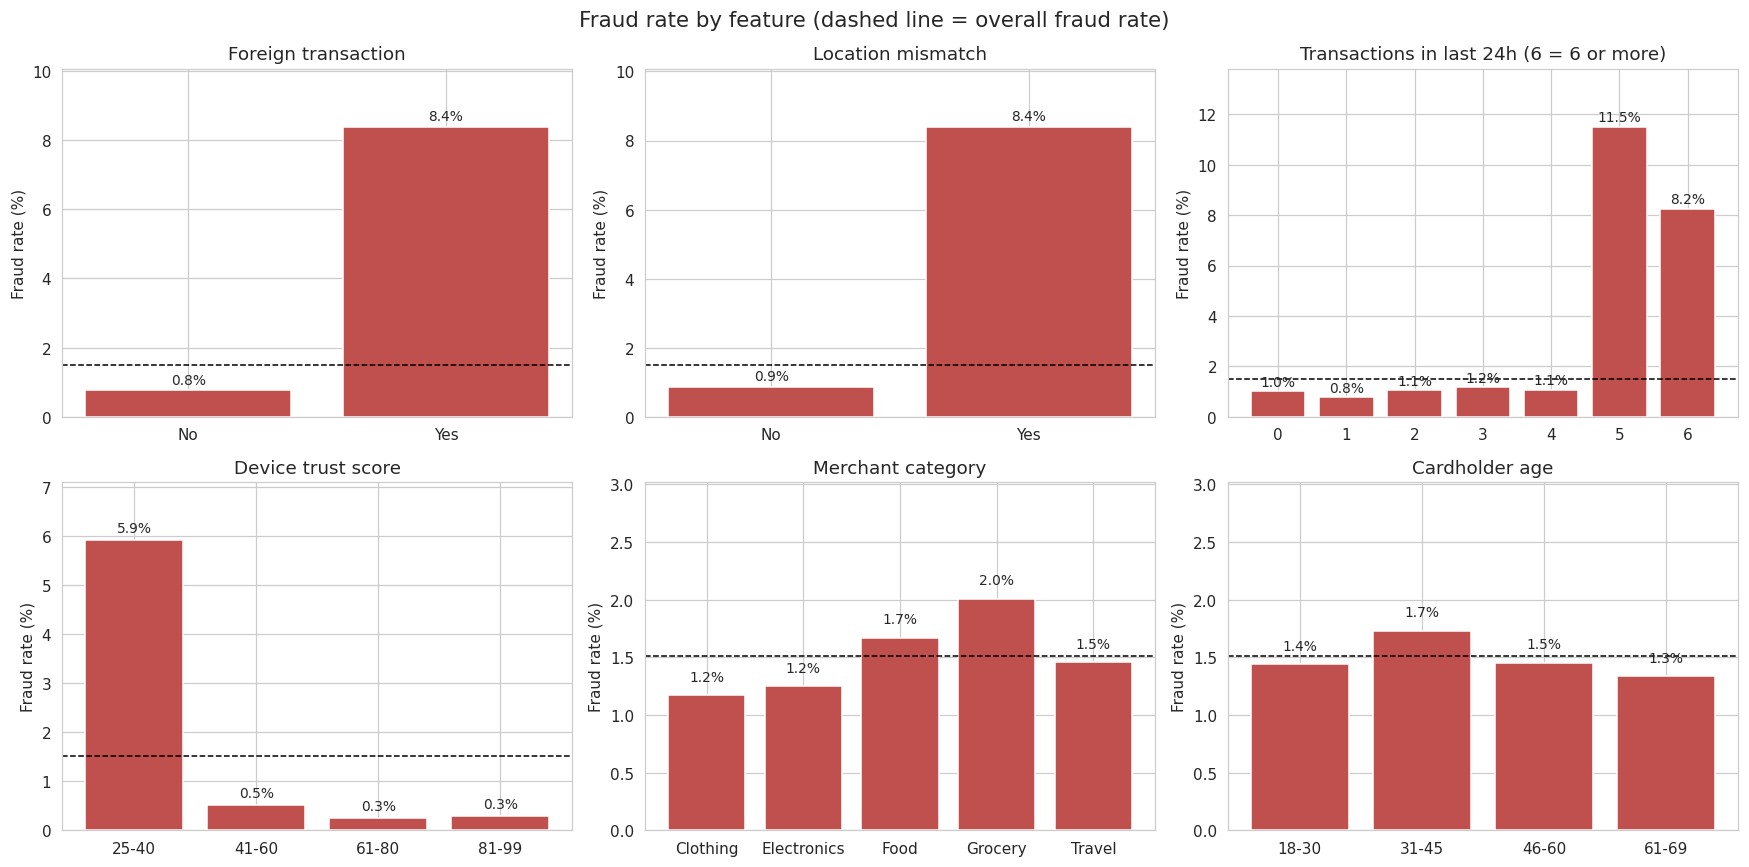

In [34]:
def rate_table(series):
    # fraud rate (%) for each value of `series`
    return df.groupby(series, observed=True)["is_fraud"].mean() * 100


panels = {
    "Foreign transaction": rate_table(df["foreign_transaction"].map({0: "No", 1: "Yes"})),
    "Location mismatch": rate_table(df["location_mismatch"].map({0: "No", 1: "Yes"})),
    "Transactions in last 24h (6 = 6 or more)": rate_table(df["velocity_last_24h"].clip(upper=6)),
    "Device trust score": rate_table(pd.cut(df["device_trust_score"], [0, 40, 60, 80, 100],
                                            labels=["25-40", "41-60", "61-80", "81-99"])),
    "Merchant category": rate_table(df["merchant_category"]),
    "Cardholder age": rate_table(pd.cut(df["cardholder_age"], [17, 30, 45, 60, 70],
                                        labels=["18-30", "31-45", "46-60", "61-69"])),
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (title, rates) in zip(axes.ravel(), panels.items()):
    ax.bar(rates.index.astype(str), rates.values, color=COLORS["Fraud"])
    ax.axhline(fraud_pct, color="black", linestyle="--", linewidth=1)
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.1, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel("Fraud rate (%)")
    ax.set_ylim(0, max(rates.max() * 1.2, fraud_pct * 2))
fig.suptitle("Fraud rate by feature (dashed line = overall fraud rate)", fontsize=14)
plt.tight_layout()
plt.show()

Correlation with is_fraud:
is_late_night          0.212
foreign_transaction    0.186
location_mismatch      0.173
device_trust_score    -0.138
velocity_last_24h      0.103
amount                 0.028
cardholder_age        -0.001


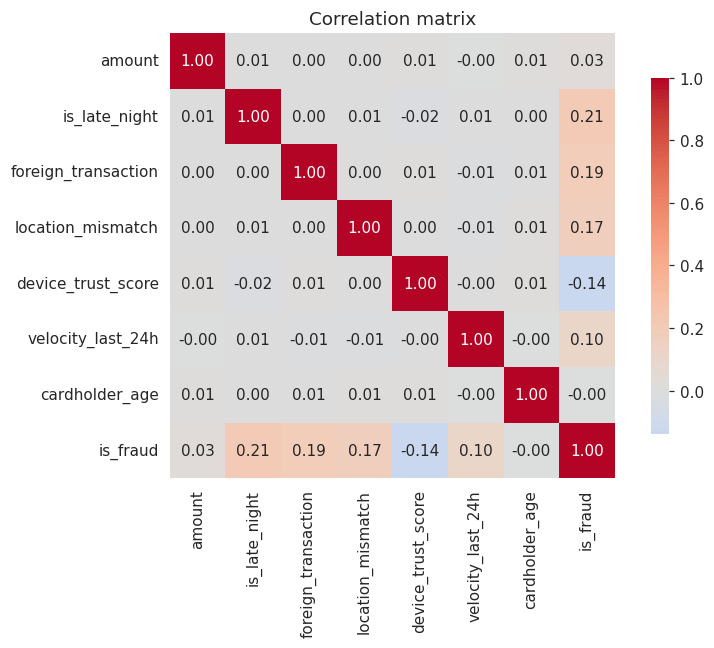

In [35]:
# correlation of every numeric feature with is_fraud
corr_cols = ["amount", "is_late_night", "foreign_transaction", "location_mismatch",
             "device_trust_score", "velocity_last_24h", "cardholder_age", "is_fraud"]
corr = df[corr_cols].corr()

print("Correlation with is_fraud:")
print(corr["is_fraud"].drop("is_fraud").sort_values(key=abs, ascending=False).round(3).to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

**Observations**

* **Foreign transaction** and **location mismatch**: fraud rate is about 8% when the flag is on, against under 1% when it is off. Each flag is on in only about 9–10% of transactions but covers roughly half of all fraud.
* **Velocity:** the fraud rate stays near 1% for up to 4 transactions in 24 hours, then jumps to around 8–12% from 5 onwards. It is a *threshold effect*, not a straight line. (The 8 and 9 bars have almost no data, so I grouped them with 6.)
* **Device trust score:** a low score (40 or below) carries a fraud rate of about 6%, against well under 1% for every higher band – and around 80% of all fraud sits in that low-trust group.
* **Merchant category** and **cardholder age** barely matter. The small differences between categories come from very few fraud cases per category, so I would not read much into them.

**Why this matters for modelling:** many of the real signals are *thresholds* (night window, 5+ transactions, low trust). A straight-line model like Logistic Regression can only partly capture them, while tree-based models can find them naturally. I will keep that in mind when comparing the models.

## 3 · Why accuracy is a misleading metric here

Accuracy = correct predictions ÷ all predictions. When 98.5% of transactions are legit, a model can get a very high accuracy **without detecting a single fraud**.

Imagine a lazy "model" that always answers *"legit"*. It would be right on every legit transaction and wrong on every fraud:

* accuracy = about **98.5%** – looks excellent
* recall (share of frauds caught) = **0%** – completely useless
* every fraud goes through, and the bank loses all that money

Accuracy treats a missed fraud and a correct "legit" as equally important, and because legit transactions are so many, they dominate the score. The difference between a good and a bad fraud model shows up only in the last 1.5% of the data, which accuracy barely notices. A model that catches 90% of fraud and one that catches 0% can differ by only around one percentage point in accuracy.

So instead of accuracy I focus on:

* **Recall** – of all real frauds, how many did we catch?
* **Precision** – of all transactions we flagged, how many were really fraud?
* **F1-score** – a single number that balances precision and recall
* **ROC-AUC** and **PR-AUC (average precision)** – how well the model ranks fraud above legit across *all* thresholds; PR-AUC is especially informative when the positive class is rare

In [36]:
# quick proof with the real numbers
naive_accuracy = n_legit / n_total
print(f"A model that always predicts 'legit' gets accuracy = {naive_accuracy:.2%}")
print("...and catches 0 of the", n_fraud, "fraud cases (recall = 0%).")

A model that always predicts 'legit' gets accuracy = 98.49%
...and catches 0 of the 151 fraud cases (recall = 0%).


## 4 · Handling the class imbalance and splitting the data

Three common ways to deal with the imbalance:

| technique | how it works | pros / cons |
|-----------|--------------|-------------|
| **`class_weight='balanced'`** | each fraud example counts much more in the loss function | simple, no data changes; the model sees only real data |
| **SMOTE** (oversampling) | creates *new, synthetic* fraud examples by interpolating between real fraud cases that are close to each other | gives the model more fraud "examples"; can add noise, and it must **never** be applied to the test data |
| **Undersampling** | throws away most legit transactions | fast, but here it would leave only ~240 rows out of 8,000 in the training set – too much information lost |

I will compare **no fix**, **class weights**, and **SMOTE**, and skip undersampling for the reason in the table.

**Two rules I follow so the results stay honest**

1. **Stratified split:** the 80/20 split keeps the same fraud percentage in the train and test set, so both contain fraud cases.
2. **SMOTE only on the training data, after the split.** The test set stays untouched (real, imbalanced) because that is what the model will meet in real life. If I applied SMOTE before splitting, synthetic copies of test frauds would leak into training and the scores would look better than they should.

Because the data has numeric *and* yes/no/category columns, I use **SMOTENC**, the SMOTE version that does not invent impossible values such as "0.37 foreign transaction".

In [37]:
num_cols = ["amount", "device_trust_score", "velocity_last_24h", "cardholder_age"]
bin_cols = ["is_late_night", "foreign_transaction", "location_mismatch"]
cat_cols = ["merchant_category"]
feature_cols = num_cols + bin_cols + cat_cols

X = df[feature_cols]
y = df["is_fraud"]

# 80/20 split, stratified so fraud appears in both parts
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train_raw):,} rows, {int(y_train.sum())} fraud ({y_train.mean():.2%})")
print(f"Test : {len(X_test_raw):,} rows, {int(y_test.sum())} fraud ({y_test.mean():.2%})")

Train: 8,000 rows, 121 fraud (1.51%)
Test : 2,000 rows, 30 fraud (1.50%)


Only **30 fraud cases** end up in the test set. That is a small number, so a single test score can move quite a bit by luck (one more or fewer caught fraud changes recall by 3 points). Because of this I also run **5-fold cross-validation** on the training data later, which validates on all 121 training fraud cases.

Preprocessing: numeric columns are standardised (needed for Logistic Regression), yes/no flags are kept as they are, and the merchant category is one-hot encoded. The preprocessor is fitted on the training data only.

In [38]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("bin", "passthrough", bin_cols),
    ("cat", OneHotEncoder(sparse_output=False), cat_cols),
])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

feature_names = [name.split("__", 1)[1] for name in preprocessor.get_feature_names_out()]
print("Features after preprocessing:", feature_names)

# SMOTENC needs to know WHICH columns are categorical/binary: everything except the scaled numeric ones.
# I pass them as a plain list of column positions. (A boolean numpy array makes recent versions of
# imbalanced-learn crash with "truth value of an array is ambiguous".)
cat_idx = list(range(len(num_cols), len(feature_names)))
print("Categorical/binary column positions for SMOTENC:", cat_idx)


def apply_resampling(X_in, y_in, mode):
    # 'smote' -> add synthetic fraud cases (training data only!), anything else -> unchanged
    if mode == "smote":
        return SMOTENC(categorical_features=cat_idx, random_state=RANDOM_STATE).fit_resample(X_in, y_in)
    return X_in, y_in


X_smote, y_smote = apply_resampling(X_train, y_train, "smote")
print(f"\nTraining set before SMOTE: {len(y_train):,} rows -> {int(y_train.sum())} fraud")
print(f"Training set after  SMOTE: {len(y_smote):,} rows -> {int(np.sum(y_smote))} fraud")

Features after preprocessing: ['amount', 'device_trust_score', 'velocity_last_24h', 'cardholder_age', 'is_late_night', 'foreign_transaction', 'location_mismatch', 'merchant_category_Clothing', 'merchant_category_Electronics', 'merchant_category_Food', 'merchant_category_Grocery', 'merchant_category_Travel']
Categorical/binary column positions for SMOTENC: [4, 5, 6, 7, 8, 9, 10, 11]

Training set before SMOTE: 8,000 rows -> 121 fraud
Training set after  SMOTE: 15,758 rows -> 7879 fraud


## 5 · Training the models

* **Logistic Regression** – a simple linear model. Fast, and its coefficients are easy to explain.
* **Random Forest** – many decision trees voting together. It can learn threshold rules and combinations of features without any manual work. (XGBoost would be another good choice, but Random Forest is enough here and needs no extra install.)

Each model is trained three ways: **no fix** (baseline), **class weights**, and **SMOTE** – six models in total, plus a "always legit" dummy model for reference.

All of them are judged at the default decision threshold of 0.5 first. Later I look at how moving the threshold changes the trade-off.

In [ ]:
RS = RANDOM_STATE


def make_logreg(weighted):
    return LogisticRegression(max_iter=2000, class_weight="balanced" if weighted else None, random_state=RS)


def make_forest(weighted):
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RS,
                                  class_weight="balanced_subsample" if weighted else None)


# name -> (function that builds a fresh model, resampling mode)
configs = {
    "LogReg - no fix":        (lambda: make_logreg(False), "none"),
    "LogReg - class_weight":  (lambda: make_logreg(True),  "none"),
    "LogReg - SMOTE":         (lambda: make_logreg(False), "smote"),
    "Forest - no fix":        (lambda: make_forest(False), "none"),
    "Forest - class_weight":  (lambda: make_forest(True),  "none"),
    "Forest - SMOTE":         (lambda: make_forest(False), "smote"),
}

results = []     # one row per model (test-set scores)
fitted = {}      # name -> trained model
probas = {}      # name -> predicted fraud probability on the test set


def score_row(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


# reference: a model that always says "legit"
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results.append(score_row("Dummy (always legit)", y_test, dummy.predict_proba(X_test)[:, 1]))

for name, (factory, resample) in configs.items():
    X_fit, y_fit = apply_resampling(X_train, y_train, resample)   # resampling touches TRAIN data only
    model = factory().fit(X_fit, y_fit)
    fitted[name] = model
    probas[name] = model.predict_proba(X_test)[:, 1]
    results.append(score_row(name, y_test, probas[name]))
    print("trained:", name)

results_df = pd.DataFrame(results).set_index("model")
results_df.round(3)

trained: LogReg - no fix
trained: LogReg - class_weight
trained: LogReg - SMOTE
trained: Forest - no fix


Look at the first row: the dummy model has an accuracy of about 98.5% – and a recall of zero. That is the accuracy trap from section 3, now shown on the real test set.

### Confusion matrices

Each matrix shows, for the 2,000 test transactions, how many legit and fraud cases were classified correctly. The bottom-left cell (**fraud predicted as legit**) is the dangerous one – a missed fraud. The top-right cell is a **false alarm**: a legit customer we wrongly flagged.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.ravel(), configs):
    pred = (probas[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Legit", "Fraud"], yticklabels=["Legit", "Fraud"])
    row = results_df.loc[name]
    ax.set_title(f"{name}\nrecall={row['recall']:.2f}  precision={row['precision']:.2f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### ROC and Precision-Recall curves

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
styles = {"LogReg": "--", "Forest": "-"}
palette = {"no fix": "#7f7f7f", "class_weight": "#2a9d8f", "SMOTE": "#e76f51"}

for name in configs:
    family, fix = [part.strip() for part in name.split(" - ")]
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    prec, rec, _ = precision_recall_curve(y_test, probas[name])
    axes[0].plot(fpr, tpr, styles[family], color=palette[fix], label=f"{name} (AUC={results_df.loc[name, 'roc_auc']:.3f})")
    axes[1].plot(rec, prec, styles[family], color=palette[fix], label=f"{name} (AP={results_df.loc[name, 'pr_auc']:.3f})")

axes[0].plot([0, 1], [0, 1], ":", color="black", label="Random guess")
axes[0].set_title("ROC curve (test set)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].axhline(y_test.mean(), linestyle=":", color="black", label=f"Random guess ({y_test.mean():.3f})")
axes[1].set_title("Precision-Recall curve (test set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

### Checking the results with 5-fold cross-validation

With only 30 fraud cases in the test set, I do not want to pick a winner from one lucky or unlucky split. So I run the cross-validation on the **training part only** (8,000 rows, 121 fraud cases): every model is trained and validated 5 times on different slices of it. The test set stays completely untouched, so I can still use it later as a final, honest check.

In each round the scaler and SMOTE are fitted on the training slice only – no leakage. I also keep the *out-of-fold* predictions (each transaction predicted by a model that never saw it); I need them later to choose the decision threshold without peeking at the test set.

In [18]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metric_names = ["precision", "recall", "f1", "roc_auc", "pr_auc"]

cv_scores = {}
oof_proba = {}      # out-of-fold fraud probabilities for every training transaction
for name, (factory, resample) in configs.items():
    fold_scores = []
    oof_proba[name] = np.zeros(len(y_train))
    for train_idx, val_idx in skf.split(X_train_raw, y_train):
        prep = clone(preprocessor).fit(X_train_raw.iloc[train_idx])
        X_tr = prep.transform(X_train_raw.iloc[train_idx])
        X_va = prep.transform(X_train_raw.iloc[val_idx])
        X_tr, y_tr = apply_resampling(X_tr, y_train.iloc[train_idx], resample)

        model = factory().fit(X_tr, y_tr)
        proba = model.predict_proba(X_va)[:, 1]
        oof_proba[name][val_idx] = proba
        pred = (proba >= 0.5).astype(int)
        y_va = y_train.iloc[val_idx]
        fold_scores.append([
            precision_score(y_va, pred, zero_division=0), recall_score(y_va, pred, zero_division=0),
            f1_score(y_va, pred, zero_division=0), roc_auc_score(y_va, proba),
            average_precision_score(y_va, proba),
        ])
    cv_scores[name] = np.array(fold_scores)

cv_mean = pd.DataFrame({n: s.mean(axis=0) for n, s in cv_scores.items()}, index=metric_names).T
cv_std = pd.DataFrame({n: s.std(axis=0) for n, s in cv_scores.items()}, index=metric_names).T

# show as "mean +- std"
cv_display = cv_mean.round(3).astype(str) + " +- " + cv_std.round(3).astype(str)
cv_display

,precision,recall,f1,roc_auc,pr_auc
LogReg - no fix,0.86 +- 0.039,0.585 +- 0.109,0.69 +- 0.066,0.996 +- 0.002,0.845 +- 0.038
LogReg - class_weight,0.364 +- 0.04,0.983 +- 0.02,0.53 +- 0.042,0.996 +- 0.001,0.826 +- 0.039
LogReg - SMOTE,0.379 +- 0.042,0.967 +- 0.031,0.542 +- 0.041,0.996 +- 0.002,0.819 +- 0.041
Forest - no fix,1.0 +- 0.0,0.57 +- 0.058,0.724 +- 0.046,1.0 +- 0.0,0.992 +- 0.008
Forest - class_weight,1.0 +- 0.0,0.562 +- 0.058,0.717 +- 0.049,0.999 +- 0.0,0.972 +- 0.019
Forest - SMOTE,0.852 +- 0.09,0.678 +- 0.068,0.753 +- 0.065,0.997 +- 0.001,0.857 +- 0.074


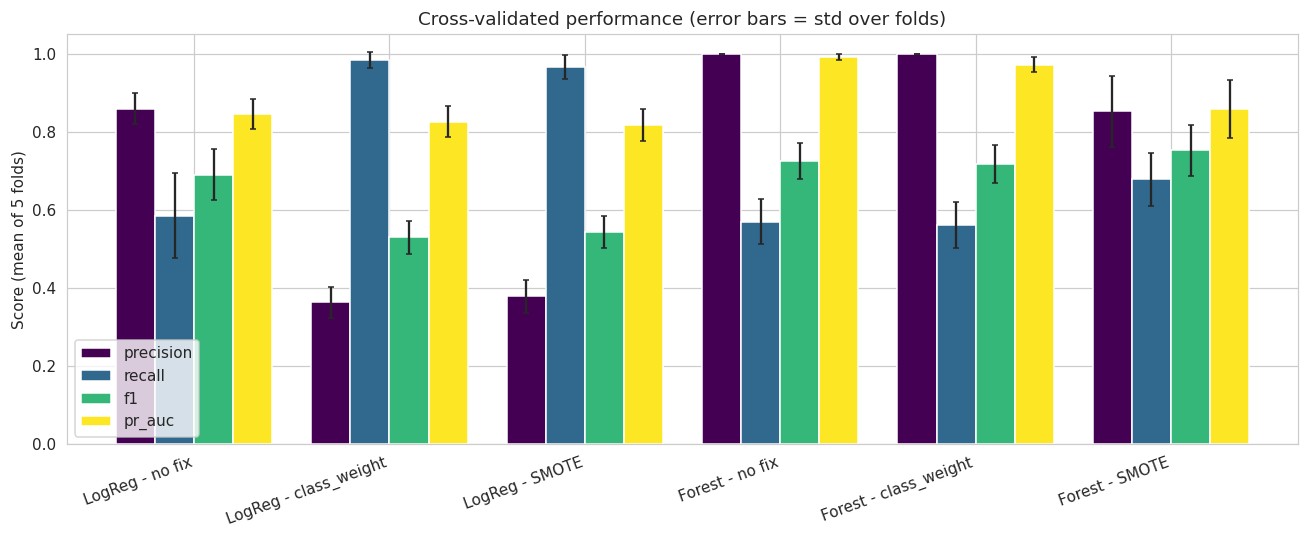

In [19]:
# bar chart of the cross-validated scores
plot_df = cv_mean[["precision", "recall", "f1", "pr_auc"]]
ax = plot_df.plot(kind="bar", figsize=(12, 5), width=0.8, colormap="viridis", edgecolor="white",
                  yerr=cv_std[["precision", "recall", "f1", "pr_auc"]].T.values, capsize=2)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score (mean of 5 folds)")
ax.set_title("Cross-validated performance (error bars = std over folds)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 6 · Which metric matters most: Recall or Precision?

The two errors a fraud model can make have very different costs:

* **False negative (a missed fraud):** the bank loses the transaction amount, and often has chargeback costs, investigation costs and an unhappy customer. This is usually the *expensive* mistake.
* **False positive (a false alarm):** a genuine customer's card gets declined or they get a verification call. It costs a little money and some annoyance – but if it happens too often, customers lose trust and switch banks, and the fraud team drowns in alerts.

Recall and precision pull in opposite directions: lowering the decision threshold catches more fraud (higher **recall**) but also flags more innocent transactions (lower **precision**).

**My view:** **recall is the primary metric** for fraud detection, because a missed fraud normally costs more than a false alarm – but only *at an acceptable precision*. A model that flags everything has perfect recall and is useless. So in practice the goal is "catch as much fraud as possible while keeping false alarms at a level the review team and the customers can accept". That is why I look at:

* **F1** as a balanced summary,
* the **PR curve / PR-AUC**, since it shows the whole recall-precision trade-off and is not fooled by the huge number of legit transactions (ROC-AUC can look great even when many false alarms are produced, because the legit class is so big),
* and the exact threshold, which is a **business decision** (how much review capacity and how much risk the bank accepts), not only a statistical one.

In [20]:
# Which model do I pick? The cross-validated PR-AUC is the most stable measure here
# (it uses all 121 training fraud cases and does not depend on a single threshold).
best_name = cv_mean["pr_auc"].idxmax()
best_model = fitted[best_name]
print("Best model by cross-validated PR-AUC:", best_name)
print(cv_mean.loc[best_name].round(3).to_string())

Best model by cross-validated PR-AUC: Forest - no fix
precision    1.000
recall       0.570
f1           0.724
roc_auc      1.000
pr_auc       0.992


### Moving the threshold

By default a transaction is flagged when the predicted fraud probability is at least 0.5, but there is nothing special about 0.5 – models trained with class weights or SMOTE even produce inflated probabilities, so for them it is clearly not the right cut-off.

To choose the threshold **without touching the test set**, I use the out-of-fold predictions from the cross-validation (training data only). The table shows what happens for the best model as the cut-off moves. `flagged_%` is the share of transactions sent for review, a rough measure of the fraud team's workload.

Since I argued that recall matters more than precision, I pick the threshold that maximises the **F2-score** – an F-score that counts recall twice as much as precision.

In [21]:
oof_best = oof_proba[best_name]          # out-of-fold probabilities on the training data
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)

rows = []
for t in grid:
    pred = (oof_best >= t).astype(int)
    rows.append({
        "threshold": t,
        "precision": precision_score(y_train, pred, zero_division=0),
        "recall": recall_score(y_train, pred, zero_division=0),
        "f1": f1_score(y_train, pred, zero_division=0),
        "f2": fbeta_score(y_train, pred, beta=2, zero_division=0),
        "flagged_%": pred.mean() * 100,
        "missed_fraud": int(((pred == 0) & (y_train == 1)).sum()),
        "false_alarms": int(((pred == 1) & (y_train == 0)).sum()),
    })
threshold_table = pd.DataFrame(rows).set_index("threshold")

chosen_threshold = float(threshold_table["f2"].idxmax())
print(f"Threshold chosen on the training data (max F2): {chosen_threshold}\n")
threshold_table.round(3)

Threshold chosen on the training data (max F2): 0.2



,precision,recall,f1,f2,flagged_%,missed_fraud,false_alarms
threshold,,,,,,,
0.05,0.255,1.000,0.407,0.632,5.925,0,353
0.10,0.529,0.992,0.690,0.844,2.838,1,107
0.15,0.821,0.983,0.895,0.946,1.812,2,26
0.20,0.951,0.967,0.959,0.964,1.538,4,6
0.25,1.000,0.909,0.952,0.926,1.375,11,0
0.30,1.000,0.802,0.890,0.835,1.213,24,0
0.35,1.000,0.736,0.848,0.777,1.112,32,0
0.40,1.000,0.678,0.808,0.724,1.025,39,0
0.45,1.000,0.645,0.784,0.694,0.975,43,0


## 7 · Feature importance and coefficient analysis

Three views of "which features matter":

* **Logistic Regression coefficients** – because the numeric features are standardised, a bigger absolute value means a stronger effect; positive = pushes towards fraud, negative = pushes away from fraud.
* **Random Forest feature importance** – how much each feature helps the trees split fraud from legit (fast, but can favour features with many different values).
* **Permutation importance** – shuffle one feature on the test set and measure how much the PR-AUC drops. This is more trustworthy because it measures the effect on real predictions.

Logistic Regression used: LogReg - no fix
Random Forest used      : Forest - no fix


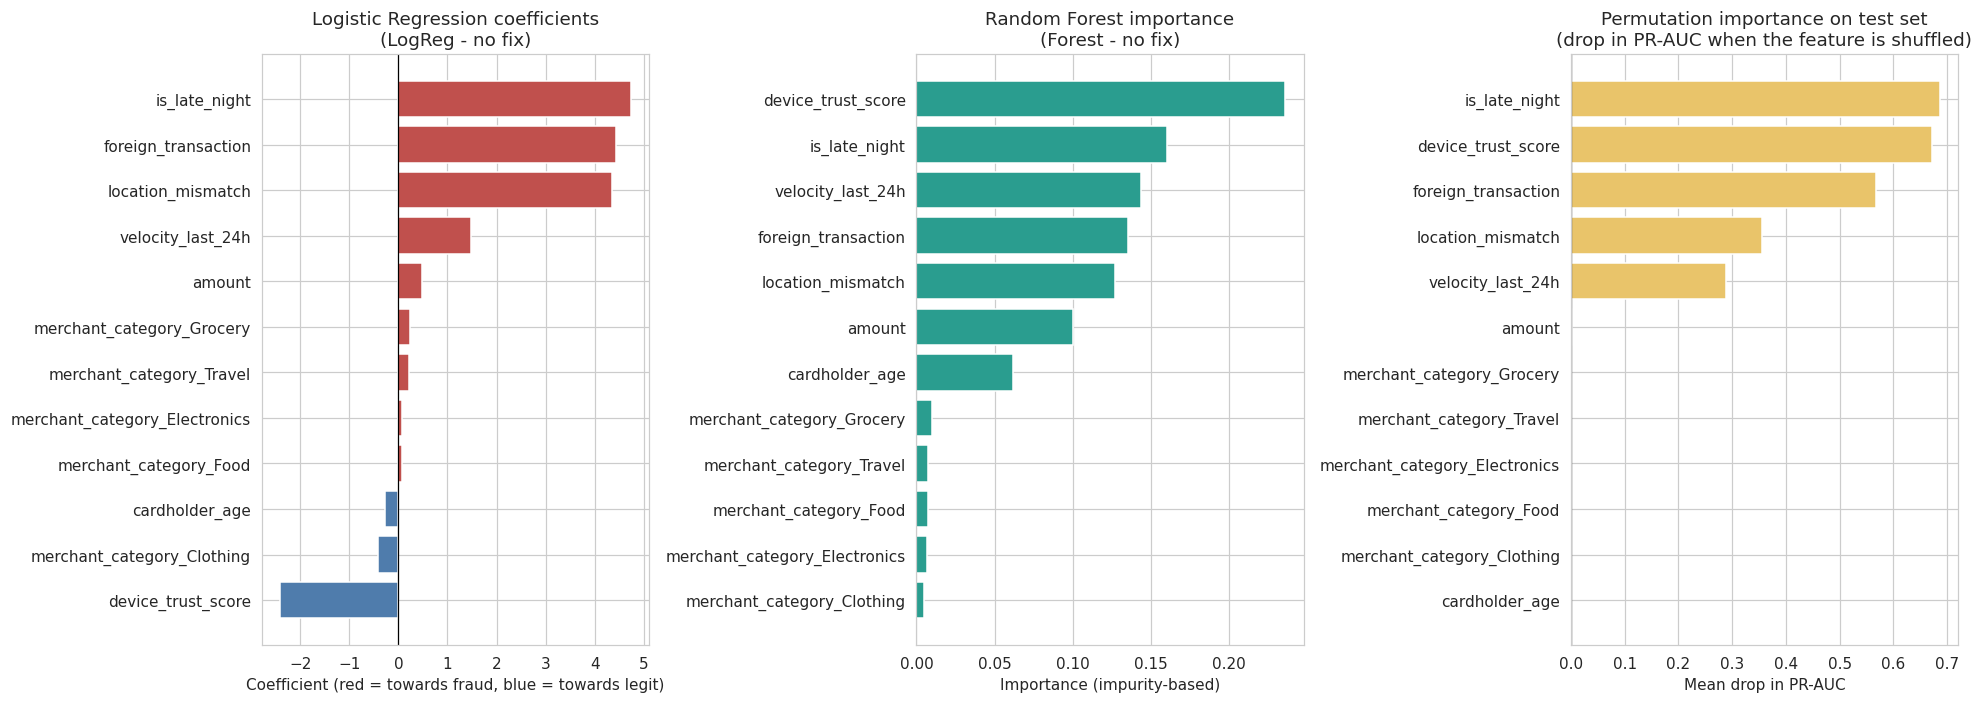

Top 5 by Random Forest importance: ['device_trust_score', 'is_late_night', 'velocity_last_24h', 'foreign_transaction', 'location_mismatch']
Top 5 by |LR coefficient|        : ['is_late_night', 'foreign_transaction', 'location_mismatch', 'device_trust_score', 'velocity_last_24h']


In [22]:
# best Logistic Regression and best Random Forest according to cross-validated PR-AUC
best_lr_name = cv_mean.loc[[n for n in configs if n.startswith("LogReg")], "pr_auc"].idxmax()
best_rf_name = cv_mean.loc[[n for n in configs if n.startswith("Forest")], "pr_auc"].idxmax()
lr_model, rf_model = fitted[best_lr_name], fitted[best_rf_name]
print("Logistic Regression used:", best_lr_name)
print("Random Forest used      :", best_rf_name)

# --- Logistic Regression coefficients ---
coef = pd.Series(lr_model.coef_[0], index=feature_names).sort_values()

# --- Random Forest: impurity importance and permutation importance ---
rf_importance = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values()
perm = permutation_importance(rf_model, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=feature_names).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))

axes[0].barh(coef.index, coef.values, color=[COLORS["Fraud"] if v > 0 else COLORS["Legit"] for v in coef.values])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title(f"Logistic Regression coefficients\n({best_lr_name})")
axes[0].set_xlabel("Coefficient (red = towards fraud, blue = towards legit)")

axes[1].barh(rf_importance.index, rf_importance.values, color="#2a9d8f")
axes[1].set_title(f"Random Forest importance\n({best_rf_name})")
axes[1].set_xlabel("Importance (impurity-based)")

axes[2].barh(perm_importance.index, perm_importance.values, color="#e9c46a")
axes[2].axvline(0, color="black", linewidth=0.8)
axes[2].set_title("Permutation importance on test set\n(drop in PR-AUC when the feature is shuffled)")
axes[2].set_xlabel("Mean drop in PR-AUC")

plt.tight_layout()
plt.show()

print("Top 5 by Random Forest importance:", list(rf_importance.sort_values(ascending=False).index[:5]))
print("Top 5 by |LR coefficient|        :", list(coef.abs().sort_values(ascending=False).index[:5]))

**Reading the charts**

* The features that matter most are the ones we found in the EDA: **late-night hours, low device trust, high velocity, foreign transaction and location mismatch**. The model has learned patterns that make business sense, not noise.
* In Logistic Regression, a **higher device trust score pushes towards legit** (negative coefficient), while the late-night flag, foreign transaction, location mismatch and higher velocity push towards fraud. The merchant-category and age coefficients are small.
* **Amount, cardholder age and merchant category** have little real importance, matching what the EDA showed. A good example of why I show three views: the Random Forest's impurity-based importance gives `amount` and `cardholder_age` a noticeable share (continuous columns offer many possible split points, which this method favours), but the permutation importance – the more reliable one – shows that shuffling them hardly changes the predictions.
* The same few features appear in all three views, which gives me more confidence in the result.

This is also useful for the business: the importance ranking can be turned into plain-language alert reasons ("flagged because: night-time + foreign + low-trust device") for the fraud analyst.

## 8 · Scalability: what if there are 1 million transactions per hour?

1,000,000 per hour is about **278 transactions per second on average**, and real traffic has peaks (sales days, evenings), so the system should be designed for several times that. First let me measure how fast the models here actually are – including the preprocessing step, since that is part of every prediction.

In [23]:
def measure_speed(model, name, n_single=200):
    # use one CPU core for prediction, like a single small server instance would
    if isinstance(model, RandomForestClassifier):
        model.set_params(n_jobs=1)

    # batch: 2,000 test rows repeated 10 times = 20,000 transactions
    batch = pd.concat([X_test_raw] * 10, ignore_index=True)
    start = time.time()
    model.predict_proba(preprocessor.transform(batch))
    batch_seconds = time.time() - start

    # one transaction at a time, like a live payment request
    start = time.time()
    for i in range(n_single):
        model.predict_proba(preprocessor.transform(X_test_raw.iloc[[i]]))
    single_ms = (time.time() - start) / n_single * 1000

    return {"model": name, "batch_tx_per_sec": len(batch) / batch_seconds, "single_tx_latency_ms": single_ms}


required_per_sec = 1_000_000 / 3600
speed_df = pd.DataFrame([measure_speed(lr_model, best_lr_name), measure_speed(rf_model, best_rf_name)]).set_index("model")
speed_df["headroom_vs_278_per_sec"] = speed_df["batch_tx_per_sec"] / required_per_sec

print(f"Required average load: {required_per_sec:.0f} transactions per second")
speed_df.round(1)

Required average load: 278 transactions per second


,batch_tx_per_sec,single_tx_latency_ms,headroom_vs_278_per_sec
model,,,
LogReg - no fix,792252.6,4.4,2852.1
Forest - no fix,94659.1,27.2,340.8


**What the numbers say:** in batch mode, even a single CPU core is able to score far more than the 278 transactions per second needed, so the model itself is **not** the bottleneck. One-at-a-time latency is higher (because of the per-call overhead of pandas and scikit-learn), but is still a few milliseconds up to tens of milliseconds, which fits into a typical real-time card authorisation budget. (Your numbers will differ with your hardware.)

**What would really be hard at 1M transactions/hour?**

1. **Real-time feature computation.** Features like `velocity_last_24h` are not in the raw transaction – they must be computed from the card's recent history in milliseconds. This is usually the hardest part. It needs a streaming pipeline (e.g. Kafka plus Flink / Spark Streaming) and a fast key-value or feature store (e.g. Redis) that keeps per-card counters up to date.
2. **Horizontal scaling.** The model is stateless, so it can be put behind a load balancer and scaled out with more instances (containers / Kubernetes autoscaling) for peak traffic. I would also set `n_jobs=1` on the forest inside each instance and scale by instance instead.
3. **Latency budget.** Payment approval usually has a total budget of around 100 ms or less. A tiered design helps: cheap rules and the lightweight model score everything, and only the uncertain cases go to slower, heavier checks or to a human analyst.
4. **Smaller / faster models.** Fewer or shallower trees, or exporting the model to a fast runtime (ONNX, compiled trees), reduce the latency per prediction. Logistic Regression is the fastest option if the latency matters more than the last few points of accuracy.
5. **Training cost.** SMOTE gets expensive with millions of rows (it needs nearest-neighbour searches). At that size I would train offline on a sample (all fraud + a sample of legit), use class weights instead, or use a gradient-boosting library, and retrain on a schedule (daily or weekly). **SMOTE is only used in training – never at prediction time.**
6. **Monitoring and drift.** Fraudsters change tactics, so the fraud pattern drifts. I would track precision/recall over time, the share of flagged transactions, and the input distributions; and retrain regularly. Real labels also arrive late (chargebacks can take weeks), so recent performance is only estimated for a while.
7. **Alert volume.** At 1M transactions per hour, even a 1% flag rate means about 10,000 alerts per hour. The review team's capacity is a hard limit on the threshold, which links back to the precision-recall trade-off above.

## 9 · Conclusion

In [24]:
print(f"Final model (best cross-validated PR-AUC): {best_name}\n")

print("Cross-validated scores on the training data (mean of 5 folds, threshold 0.5):")
print(cv_mean.loc[best_name].round(3).to_string())

# final, untouched test set: default threshold vs. the threshold tuned on the training data
default_row = score_row("default", y_test, probas[best_name], threshold=0.5)
tuned_row = score_row("tuned", y_test, probas[best_name], threshold=chosen_threshold)

for label, row in [("default threshold 0.5", default_row),
                   (f"tuned threshold {chosen_threshold}", tuned_row)]:
    print(f"\nTest set, {label}:")
    print(f"  frauds caught : {int(row['TP'])} of {int(row['TP'] + row['FN'])}")
    print(f"  false alarms  : {int(row['FP'])} out of {int(row['FP'] + row['TN'])} legit transactions")
    print(f"  precision {row['precision']:.3f} | recall {row['recall']:.3f} | F1 {row['f1']:.3f}")
print(f"\nROC-AUC on the test set: {default_row['roc_auc']:.3f} | PR-AUC: {default_row['pr_auc']:.3f}")

print("\nAll models ranked by cross-validated PR-AUC:")
print(cv_mean["pr_auc"].sort_values(ascending=False).round(3).to_string())

Final model (best cross-validated PR-AUC): Forest - no fix

Cross-validated scores on the training data (mean of 5 folds, threshold 0.5):
precision    1.000
recall       0.570
f1           0.724
roc_auc      1.000
pr_auc       0.992

Test set, default threshold 0.5:
  frauds caught : 21 of 30
  false alarms  : 0 out of 1970 legit transactions
  precision 1.000 | recall 0.700 | F1 0.824

Test set, tuned threshold 0.2:
  frauds caught : 30 of 30
  false alarms  : 0 out of 1970 legit transactions
  precision 1.000 | recall 1.000 | F1 1.000

ROC-AUC on the test set: 1.000 | PR-AUC: 1.000

All models ranked by cross-validated PR-AUC:
Forest - no fix          0.992
Forest - class_weight    0.972
Forest - SMOTE           0.857
LogReg - no fix          0.845
LogReg - class_weight    0.826
LogReg - SMOTE           0.819


### Summary of findings

**The data**

* Fraud is only about **1.5%** of transactions. A model that always says "legit" is 98.5% accurate and catches nothing, so accuracy was ignored and recall, precision, F1, ROC-AUC and PR-AUC were used instead.
* Fraud follows clear patterns: it happens **late at night (00:00–03:59)**, on **low-trust devices**, with **foreign** or **location-mismatched** transactions, and after **5 or more transactions in 24 hours**. The transaction **amount, age and merchant category** hardly separate fraud from legit.

**The models** *(statements about numbers refer to my run – check the tables above for yours)*

* **Random Forest is clearly better than Logistic Regression.** Many fraud signals are thresholds (a night window, 5+ transactions, a trust cut-off) that trees capture naturally and a straight-line model only approximates.
* A useful detail: the **ROC-AUC of Logistic Regression is about 0.996 – almost as high as the forest – yet its PR-AUC is far lower**. ROC-AUC looks great on rare-event data because the huge legit class keeps the false-positive *rate* tiny, even when there are many false alarms. This is exactly why PR-AUC is the better yardstick here.
* **Class weights and SMOTE do not make the model "smarter" – they mainly move its operating point.** For Logistic Regression, class weights push recall to almost 100%, but precision falls to roughly 0.4 (more than one false alarm for each fraud caught) and PR-AUC does not improve. A similar cut-off could be reached by simply lowering the threshold. Balancing helps most when the default 0.5 cut-off is too strict for the model, as it is for the plain forest.
* Because of this, **choosing the threshold is as important as choosing the model**. I selected it from out-of-fold predictions on the training data and only then checked it once on the test set.

**Caveats**

* Only 121 fraud cases are available for training and 30 for the test set, so every score has noticeable uncertainty – this is why I rely on cross-validation and show the standard deviation.
* The data is very clean (no missing values, very clear fraud rules, ROC-AUC close to 1.0). Real transaction data is messier, and real fraudsters adapt, so scores on live data would almost certainly be lower.

### Real-world application

A model like this can sit inside a **card or UPI / wallet payment authorisation flow**, scoring each transaction in milliseconds and deciding to *approve*, *decline*, or *ask for extra verification (OTP / call)*. The same idea works for e-commerce order screening, insurance claims and account-takeover detection. In production the score would feed a rules engine and a human review queue, with the threshold set by how many alerts the review team can handle – together with the retraining and monitoring discussed in section 8.